# Predictive model that predicts whether the student will pass the exam


1) Importing required libraries

In [787]:
import pandas as pd
import numpy as np
import warnings

In [788]:
warnings.filterwarnings("ignore")

In [789]:
df = pd.read_csv('data/studentInfo.csv')

df.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [790]:
df[['final_result']]

,final_result
0,Pass
1,Pass
2,Withdrawn
3,Pass
4,Pass
...,...
32588,Fail
32589,Distinction
32590,Pass
32591,Withdrawn


2. Define input and output data

In [792]:

X = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [793]:
X.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N


In [794]:
X.dtypes

code_module             object
code_presentation       object
id_student               int64
gender                  object
region                  object
highest_education       object
imd_band                object
age_band                object
num_of_prev_attempts     int64
studied_credits          int64
disability              object
dtype: object

In [795]:
all_values = df['highest_education'].unique()
print(all_values)

['HE Qualification' 'A Level or Equivalent' 'Lower Than A Level'
 'Post Graduate Qualification' 'No Formal quals']


In [796]:
all_values = df['imd_band'].unique()
print(all_values)

['90-100%' '20-30%' '30-40%' '50-60%' '80-90%' '70-80%' nan '60-70%'
 '40-50%' '10-20' '0-10%']


In [797]:
all_values = df['age_band'].unique()
print(all_values)

['55<=' '35-55' '0-35']


In [798]:
all_values = df['code_module'].unique()
print(all_values)

['AAA' 'BBB' 'CCC' 'DDD' 'EEE' 'FFF' 'GGG']


In [799]:
df[['code_presentation','id_student','gender','region','disability']].head()

,code_presentation,id_student,gender,region,disability
0,2013J,11391,M,East Anglian Region,N
1,2013J,28400,F,Scotland,N
2,2013J,30268,F,North Western Region,Y
3,2013J,31604,F,South East Region,N
4,2013J,32885,F,West Midlands Region,N


In [800]:
dummy_qual = pd.get_dummies(df['highest_education']).astype(int)
dummy_imd = pd.get_dummies(df['imd_band']).astype(int)
dummy_age = pd.get_dummies(df['age_band']).astype(int)
dummy_module = pd.get_dummies(df['code_module']).astype(int)

In [801]:
dummy = pd.concat([dummy_qual,dummy_imd,dummy_age,dummy_module],axis = 1)
dummy.head()

,A Level or Equivalent,HE Qualification,Lower Than A Level,No Formal quals,Post Graduate Qualification,0-10%,10-20,20-30%,30-40%,40-50%,...,0-35,35-55,55<=,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,0,1,0,0,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
1,0,1,0,0,0,0,0,1,0,0,...,0,1,0,1,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,1,0,1,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [802]:
X.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N


In [803]:
X = pd.concat([X,dummy],axis = 1)
X.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,0-35,35-55,55<=,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,0,0,1,1,0,0,0,0,0,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,1,0,0,1,0,0,0,0,0,0


In [804]:
X.dtypes

code_module                    object
code_presentation              object
id_student                      int64
gender                         object
region                         object
highest_education              object
imd_band                       object
age_band                       object
num_of_prev_attempts            int64
studied_credits                 int64
disability                     object
A Level or Equivalent           int32
HE Qualification                int32
Lower Than A Level              int32
No Formal quals                 int32
Post Graduate Qualification     int32
0-10%                           int32
10-20                           int32
20-30%                          int32
30-40%                          int32
40-50%                          int32
50-60%                          int32
60-70%                          int32
70-80%                          int32
80-90%                          int32
90-100%                         int32
0-35        

In [805]:
X.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,0-35,35-55,55<=,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,0,0,1,1,0,0,0,0,0,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,1,0,0,1,0,0,0,0,0,0


In [806]:
y.head()

0         Pass
1         Pass
2    Withdrawn
3         Pass
4         Pass
Name: final_result, dtype: object

In [807]:
all_values = df['final_result'].unique()
print(all_values)

['Pass' 'Withdrawn' 'Fail' 'Distinction']


In [808]:
df['final_result'] = df['final_result'].isin(['Pass','Distincion']).astype(bool)

In [809]:
y = df.iloc[:,-1]
print(y)

0         True
1         True
2        False
3         True
4         True
         ...  
32588    False
32589    False
32590     True
32591    False
32592    False
Name: final_result, Length: 32593, dtype: bool


In [810]:
X = X.fillna(X.mean)
X.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,0-35,35-55,55<=,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,0,0,1,1,0,0,0,0,0,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,0,1,0,1,0,0,0,0,0,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,1,0,0,1,0,0,0,0,0,0


In [940]:
X = X.select_dtypes(include=['int32','int64', 'float64'])
X.head()

,num_of_prev_attempts,studied_credits,A Level or Equivalent,HE Qualification,Lower Than A Level,No Formal quals,Post Graduate Qualification,0-10%,10-20,20-30%,...,0-35,35-55,55<=,AAA,BBB,CCC,DDD,EEE,FFF,GGG
0,0,240,0,1,0,0,0,0,0,0,...,0,0,1,1,0,0,0,0,0,0
1,0,60,0,1,0,0,0,0,0,1,...,0,1,0,1,0,0,0,0,0,0
2,0,60,1,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
3,0,60,1,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,0
4,0,60,0,0,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [812]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

In [813]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [814]:
from sklearn.model_selection import cross_validate, cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay

In [815]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [816]:
models = {
    'LogisticRegression': LogisticRegression(),
    'DecisionTreeClassifier': DecisionTreeClassifier(),
    'RandomForestClassifier': RandomForestClassifier(),
    'GradientBoostingClassifier': GradientBoostingClassifier()
}
results = []

for name,model in models.items() :
        cv_scores = cross_validate(model, X, y, scoring = ['accuracy', 'roc_auc'], cv=10, return_train_score = True)
        results.append({
            'Algorithm':name,
            'AUC':cv_scores['test_roc_auc'].mean(),
            'AUC SD':cv_scores['test_roc_auc'].std(),
            'Acc':cv_scores['test_accuracy'].mean(),
            'Acc SD':cv_scores['test_accuracy'].std()
        })
                        

results_df = pd.DataFrame(results)
results_df

,Algorithm,AUC,AUC SD,Acc,Acc SD
0,LogisticRegression,0.587136,0.053644,0.585522,0.070703
1,DecisionTreeClassifier,0.539857,0.038032,0.565518,0.066155
2,RandomForestClassifier,0.547150,0.036777,0.564537,0.066823
3,GradientBoostingClassifier,0.585769,0.052853,0.587302,0.071482


In [817]:
model = LogisticRegression()
model.fit(X, y)

LogisticRegression()

In [818]:
pred_proba = model.predict_proba(X)
pd.DataFrame(pred_proba)

,0,1
0,0.550257,0.449743
1,0.339024,0.660976
2,0.296735,0.703265
3,0.288434,0.711566
4,0.384603,0.615397
...,...,...
32588,0.643734,0.356266
32589,0.589573,0.410427
32590,0.549998,0.450002
32591,0.550304,0.449696


In [819]:
y_pred = model.predict(X)
y_pred_proba = model.predict_proba(X)

accuracy_score = accuracy_score(y, y_pred)
precision_score = precision_score(y, y_pred)
recal_score = recall_score(y, y_pred)
f1_score = f1_score(y, y_pred)
roc_auc_score = roc_auc_score(y, y_pred_proba[:, 1])

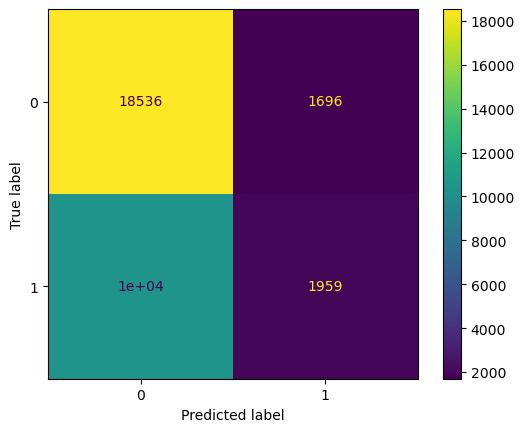

In [820]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

def confusion_matrix_plot(y, y_pred):
    disp = ConfusionMatrixDisplay(confusion_matrix(y, y_pred))
    disp.plot()
    plt.show()

confusion_matrix_plot(y, y_pred)

In [821]:
model.predict(X)

array([False,  True,  True, ..., False, False,  True])

In [822]:
print(np.unique(model.predict(X)))
print(np.bincount(model.predict(X)))

[False  True]
[28938  3655]


In [823]:
confusion_matrix(y_true = y, y_pred = model.predict(X))

array([[18536,  1696],
       [10402,  1959]], dtype=int64)

In [824]:
from sklearn.metrics import accuracy_score
acc_score = accuracy_score(y, model.predict(X))

f'Model je {round(acc_score*100,2)}% tacan'

'Model je 62.88% tacan'

In [825]:
accuracy_score(y, np.repeat(0,len(y)))

0.620746786119719

In [826]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_hat = model.predict(X)

def performance(model, y, y_hat):
    acc = accuracy_score(y, y_hat)
    prec = precision_score(y, y_hat)
    rec = recall_score(y, y_hat)
    f1 = f1_score(y, y_hat)
    res = {'Algorithm':model,
        'Accuracy':[acc],
        'Precision':[prec],
        'Recall':[rec],
        'F1':[f1]}
    return res
    
pd.DataFrame(performance(model, y, y_hat))

,Algorithm,Accuracy,Precision,Recall,F1
0,LogisticRegression(),0.628816,0.535978,0.158482,0.24463


In [827]:
def print_performance(y, y_hat):
    print(f'Accuracy: {accuracy_score(y, y_hat)}')
    print(f'Precision: {precision_score(y, y_hat)}')
    print(f'Recall: {recall_score(y, y_hat)}')
    print(f'F1: {f1_score(y, y_hat)}')

In [828]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

In [829]:
models = [GaussianNB(), KNeighborsClassifier(),DecisionTreeClassifier()]

def show_performance(models, X_train, y_train, X_test, y_test):
    results = []
    for model in models:
        model.fit(X_train, y_train)
        y_hat = model.predict(X_test)
        results.append(performance(model, y_test, y_hat))
    return results

pd.DataFrame(show_performance(models, X, y, X, y))

,Algorithm,Accuracy,Precision,Recall,F1
0,GaussianNB(),[0.6047003957905072],[0.4767865068797159],[0.4345117708923226],[0.45466858545670025]
1,KNeighborsClassifier(),[0.621789954898291],[0.5016034710431994],[0.43022409190194966],[0.46317989809693855]
2,DecisionTreeClassifier(),[0.6797165035437057],[0.6597406914893617],[0.3210905266564194],[0.4319529847091473]


In [830]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state =  2019)
models.append(LogisticRegression())
pd.DataFrame(show_performance(models, X_train, y_train, X_test, y_test))

,Algorithm,Accuracy,Precision,Recall,F1
0,GaussianNB(),[0.6112900751649026],[0.47829899167032003],[0.4480492813141684],[0.4626802374893978]
1,KNeighborsClassifier(),[0.5737076238686916],[0.41425722831505485],[0.3412731006160164],[0.37424003602792166]
2,DecisionTreeClassifier(),[0.603466789384875],[0.4446085672082718],[0.24722792607802874],[0.31776194246503037]
3,LogisticRegression(),[0.6349133302653781],[0.5344180225281602],[0.1753593429158111],[0.26406926406926406]


In [831]:
from sklearn.model_selection import KFold

In [832]:
folds = KFold(n_splits=10)
results = []

for train_index, test_index in folds.split(X):
    X_train, y_train = X.loc[train_index,:], y[train_index]
    X_test, y_test = X.loc[test_index], y[test_index]

    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_hat = model.predict(X_test)
    results.append(performance(model, y_test, y_hat))
pd.DataFrame(results)

,Algorithm,Accuracy,Precision,Recall,F1
0,LogisticRegression(),[0.5585889570552147],[0.4759825327510917],[0.07633053221288516],[0.1315630657815329]
1,LogisticRegression(),[0.6211656441717791],[0.4936708860759494],[0.1903986981285598],[0.2748091603053435]
2,LogisticRegression(),[0.6423312883435582],[0.5621621621621622],[0.08746846089150546],[0.15138282387190685]
3,LogisticRegression(),[0.7278306228904572],[0.0],[0.0],[0.0]
4,LogisticRegression(),[0.6366983737342743],[0.0],[0.0],[0.0]
5,LogisticRegression(),[0.6501994476833385],[0.5376344086021505],[0.043591979075850044],[0.08064516129032258]
6,LogisticRegression(),[0.5636698373734275],[0.49648162627052383],[0.44939844302901627],[0.47176820208023773]
7,LogisticRegression(),[0.5992635777845965],[0.5],[0.08422664624808576],[0.14416775884665792]
8,LogisticRegression(),[0.6231972997852102],[0.47058823529411764],[0.0989282769991756],[0.16348773841961853]
9,LogisticRegression(),[0.5685793188094508],[0.46971935007385524],[0.23296703296703297],[0.31145935357492655]


In [833]:
accuracies = [res['Accuracy'][0] for res in results]

In [834]:
f'Accuracy is {round(np.mean(accuracies)*100,2)}% +/- {round(np.std(accuracies)*100,2)}%'

'Accuracy is 61.92% +/- 4.83%'

In [835]:
from sklearn.model_selection import cross_val_score
model = model = LogisticRegression()
results = cross_val_score(model, X, y, cv=10, scoring='accuracy')
f'Accuracy is {round(np.mean(results)*100,2)}% +/- {round(np.std(results)*100,2)}%'

'Accuracy is 58.55% +/- 7.07%'

In [836]:
model = LogisticRegression().fit(X ,y)
y_hat = model.predict_proba(X)
y_hat

array([[0.55025718, 0.44974282],
       [0.33902431, 0.66097569],
       [0.29673492, 0.70326508],
       ...,
       [0.54999836, 0.45000164],
       [0.55030413, 0.44969587],
       [0.48577699, 0.51422301]])

In [837]:
res = pd.DataFrame({'stvarno':y,'predvidjeno':y_hat[:,1]})
res.head()

,stvarno,predvidjeno
0,True,0.449743
1,True,0.660976
2,False,0.703265
3,True,0.711566
4,True,0.615397


In [838]:
def predict_compare(model, X, y, limit):
    results = []    
    y_hat = model.predict(X)
    results.append(performance(model, y, y_hat))
    y_hat = model.predict_proba(X)[:,1]>=limit
    results.append(performance(model, y, y_hat))
    rp = pd.DataFrame({'Function':['predict','predict_proba']})
    results = pd.DataFrame(results)
    results = pd.concat([results,rp],axis = 1)
    results.set_index('Function',inplace=True)
    return results,y_hat

res,y_hat = predict_compare(model, X, y, 0.5)
res

,Algorithm,Accuracy,Precision,Recall,F1
Function,,,,,
predict,LogisticRegression(),[0.6288160034363207],[0.5359781121751026],[0.15848232343661517],[0.24463036963036963]
predict_proba,LogisticRegression(),[0.6288160034363207],[0.5359781121751026],[0.15848232343661517],[0.24463036963036963]


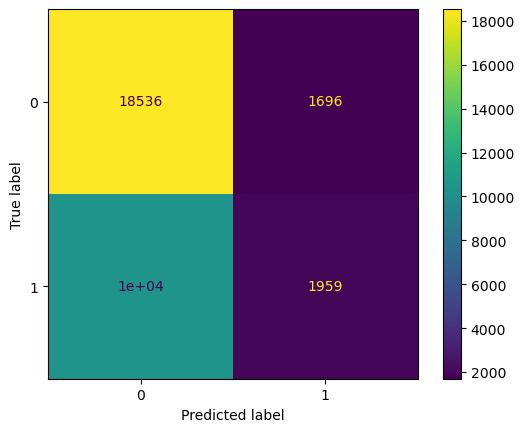

In [839]:
confusion_matrix_plot(y, y_hat)

In [840]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y, model.predict_proba(X)[:,1])

0.6242676590575296

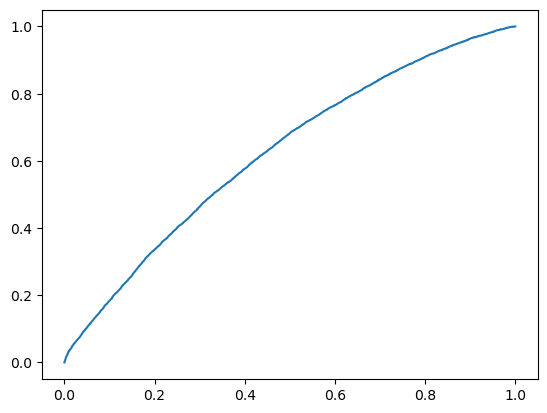

In [841]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fpr ,tpr, thresholds = roc_curve(y, model.predict_proba(X)[:,1])

plt.plot(fpr,tpr)

plt.show()

In [842]:
results = cross_val_score(model, X, y, cv=10, scoring='roc_auc')

print(results.mean())
print(results.std())

0.5871361882722866
0.053643569069895876


In [843]:
X.dtypes

num_of_prev_attempts           int64
studied_credits                int64
A Level or Equivalent          int32
HE Qualification               int32
Lower Than A Level             int32
No Formal quals                int32
Post Graduate Qualification    int32
0-10%                          int32
10-20                          int32
20-30%                         int32
30-40%                         int32
40-50%                         int32
50-60%                         int32
60-70%                         int32
70-80%                         int32
80-90%                         int32
90-100%                        int32
0-35                           int32
35-55                          int32
55<=                           int32
AAA                            int32
BBB                            int32
CCC                            int32
DDD                            int32
EEE                            int32
FFF                            int32
GGG                            int32
d

1. Check P-Values (Statistical Significance)
Logistic Regression assumes a linear relationship between features and the log-odds of the target. If a feature has a high p-value, it likely does not contribute much to the model.

    *Steps:
   
    1)Fit a logistic regression model.
   
    2)Use statsmodels to check p-values.
   
    3)Remove features with p-value > 0.05 (not statistically significant).

In [845]:
import statsmodels.api as sm
rf = model.fit(X,y)

In [846]:
X_const = sm.add_constant(X)
logit_model = sm.Logit(y, X_const).fit()

Optimization terminated successfully.
         Current function value: 0.639767
         Iterations 6


In [847]:
print(logit_model.pvalues)

const                                   NaN
num_of_prev_attempts           1.958910e-19
studied_credits                1.474763e-56
A Level or Equivalent                   NaN
HE Qualification                        NaN
Lower Than A Level                      NaN
No Formal quals                         NaN
Post Graduate Qualification             NaN
0-10%                          8.192157e-29
10-20                          3.239362e-22
20-30%                         7.877060e-21
30-40%                         1.879900e-12
40-50%                         1.371456e-13
50-60%                         1.198490e-10
60-70%                         3.313163e-07
70-80%                         2.486592e-09
80-90%                         1.422196e-06
90-100%                        7.874245e-06
0-35                                    NaN
35-55                                   NaN
55<=                                    NaN
AAA                                     NaN
BBB                             

In [988]:
p_values = logit_model.pvalues
useless_columns = p_values[p_values.isna()].index
useless_columns

Index(['const', 'A Level or Equivalent', 'HE Qualification',
       'Lower Than A Level', 'No Formal quals', 'Post Graduate Qualification',
       '0-35', '35-55', '55<=', 'AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF',
       'GGG'],
      dtype='object')

In [990]:
useless_columns = ['A Level or Equivalent', 'HE Qualification',
       'Lower Than A Level', 'No Formal quals', 'Post Graduate Qualification',
       '0-35', '35-55', '55<=', 'AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF',
       'GGG']
X_cleaned = X.drop(columns = useless_columns)
X_cleaned.head()

,num_of_prev_attempts,studied_credits,0-10%,10-20,20-30%,30-40%,40-50%,50-60%,60-70%,70-80%,80-90%,90-100%
0,0,240,0,0,0,0,0,0,0,0,0,1
1,0,60,0,0,1,0,0,0,0,0,0,0
2,0,60,0,0,0,1,0,0,0,0,0,0
3,0,60,0,0,0,0,0,1,0,0,0,0
4,0,60,0,0,0,0,0,1,0,0,0,0


In [994]:
model = LogisticRegression()
model.fit(X_cleaned,y)

LogisticRegression()

In [1054]:
res_cleaned,y_hat = predict_compare(model, X_cleaned, y, 0.40)
res_cleaned

,Algorithm,Accuracy,Precision,Recall,F1
Function,,,,,
predict,LogisticRegression(),[0.6218206363329549],[0.5186368477103301],[0.03939810694927595],[0.07323308270676691]
predict_proba,LogisticRegression(),[0.5703985518362839],[0.4442632973303444],[0.5290834074913033],[0.482977623513773]


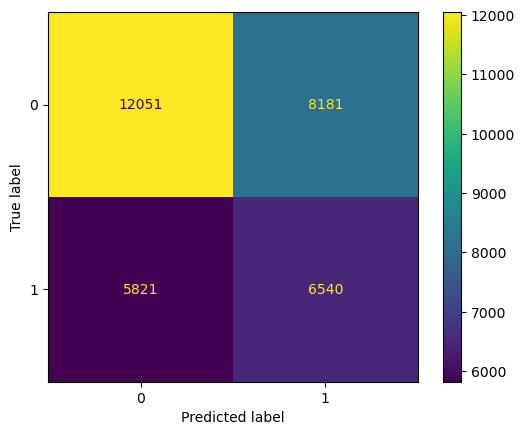

In [1056]:
confusion_matrix_plot(y, y_hat)

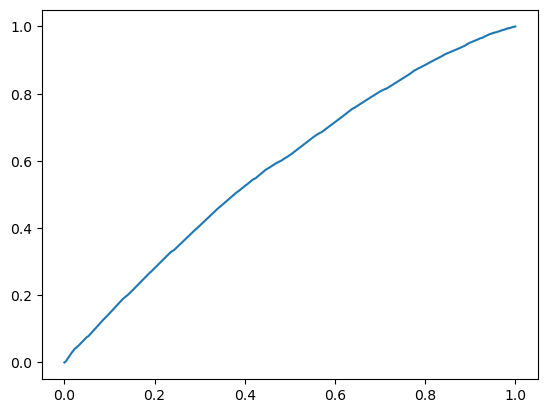

In [1058]:
fpr ,tpr, thresholds = roc_curve(y, model.predict_proba(X_cleaned)[:,1])

plt.plot(fpr,tpr)

plt.show()

In [848]:
useless_columns_1 = logit_model.pvalues[logit_model.pvalues > 0.05].index
print("Useless features:", useless_columns_1)

Useless features: Index([], dtype='object')


In [849]:
feature_importance = pd.Series(model.coef_[0], index=X.columns)
print(feature_importance.sort_values())

CCC                           -0.703444
0-10%                         -0.587254
10-20                         -0.488118
No Formal quals               -0.468498
20-30%                        -0.466994
40-50%                        -0.321835
30-40%                        -0.292199
num_of_prev_attempts          -0.260202
50-60%                        -0.252093
70-80%                        -0.230685
DDD                           -0.167879
60-70%                        -0.164358
90-100%                       -0.161536
80-90%                        -0.160091
55<=                          -0.080940
GGG                           -0.068557
Lower Than A Level            -0.064503
studied_credits               -0.005345
FFF                            0.017903
BBB                            0.041719
Post Graduate Qualification    0.062342
0-35                           0.068666
EEE                            0.082346
35-55                          0.131791
HE Qualification               0.284860


In [850]:
useless_columns_2 = feature_importance[abs(feature_importance)<0.01].index
print("Useless features:", useless_columns_2)

Useless features: Index(['studied_credits'], dtype='object')


In [851]:
correlation = X.corrwith(y)
print(correlation.sort_values())

studied_credits               -0.105391
CCC                           -0.092520
Lower Than A Level            -0.078001
num_of_prev_attempts          -0.069281
0-10%                         -0.054360
10-20                         -0.033929
0-35                          -0.032217
20-30%                        -0.032026
No Formal quals               -0.027480
DDD                           -0.024330
40-50%                        -0.002288
Post Graduate Qualification   -0.001106
30-40%                         0.000574
FFF                            0.005083
55<=                           0.007857
50-60%                         0.009067
BBB                            0.011430
70-80%                         0.017410
60-70%                         0.023806
80-90%                         0.026680
HE Qualification               0.029825
35-55                          0.031026
90-100%                        0.032863
GGG                            0.037069
EEE                            0.040050


In [920]:
useless_columns_3 = correlation[abs(correlation) > 0.05].index
print("Useless features:", useless_columns_3)

Useless features: Index(['num_of_prev_attempts', 'studied_credits', 'A Level or Equivalent',
       'Lower Than A Level', '0-10%', 'AAA', 'CCC'],
      dtype='object')
